# Lab Assignment 7: LSTM-Based Sequence Tagging

**Student:** Muhammad Obaidullah (abdulsalam.m@northeastern.edu)  
**Course:** Applied NLP  
**Submission:** Upload `Lab_7.ipynb` to Canvas with all cells run and outputs visible.

---

## Overview

Sequence tagging — assigning a label to every token in a sentence — is one of the most practically important NLP tasks. Named Entity Recognition (NER), Part-of-Speech tagging, and chunking all follow the same structure: a model reads a sequence of tokens left to right (and, in a bidirectional model, right to left) and emits a tag for each position.

The LSTM was designed to solve the vanishing gradient problem that makes plain RNNs difficult to train on long sequences. Its gating mechanism lets the model learn which information to carry forward and which to discard. But how much does that actually help compared to a plain RNN, and how does a GRU — a simpler gating design — compare? In this lab you will answer those questions empirically.

You will also encounter teacher forcing — a training strategy for sequence-to-sequence decoders — and observe firsthand the tension it creates between training stability and inference-time generalization.

---

## Learning Objectives

1. Implement an LSTM-based sequence tagger for NER and evaluate it using span-level F1, interpreting precision/recall trade-offs
2. Compare RNN, LSTM, and GRU architectures by analyzing how each addresses the vanishing gradient problem differently
3. Assess the effect of teacher forcing on training stability and generalization in sequence-to-sequence tasks
4. Diagnose characteristic failure patterns in LSTM-based taggers and justify architectural or data modifications to address them

---

## Grading

| Component | Points | Method |
|---|---|---|
| Part 1 — LSTM tagger and span F1 | 26 | Autograded (20) + Manual (6) |
| Part 2 — RNN vs LSTM vs GRU | 22 | Autograded (16) + Manual (6) |
| Part 3 — Teacher forcing | 20 | Autograded (14) + Manual (6) |
| Part 4 — Failure pattern diagnosis | 18 | Autograded (12) + Manual (6) |
| Code quality | 14 | Manual |
| **Total** | **100** | |

### Manual grading rubric

**Reflections (6 pts each):**  
Full credit requires a specific, evidence-grounded claim with a concrete mechanism and precise NLP terminology. Restating the numbers earns 1–2 pts. Naming the mechanism and its downstream consequence earns 5–6 pts.

**Code quality (14 pts):**

| Criterion | Points |
|---|---|
| Docstrings and inline comments | 4 |
| Function design | 4 |
| Defensive coding | 3 |
| Code clarity and naming | 2 |
| Avoiding redundancy | 1 |

---

## Setup

In [1]:
# Setup — run this cell first every session.

import subprocess, sys
from importlib import metadata

def install_if_missing(package, pip_name=None):
    """Install a package if it is missing or does not match a pinned version.

    The installed version is read from package metadata instead of by
    importing, so a pin such as "datasets==3.5.0" still replaces a newer
    preinstalled release (as on Colab) before the first import.

    Args:
        package  (str): The importable module name to check.
        pip_name (str): pip install name if different from package; may
                        carry a version pin, e.g. "datasets==3.5.0".
    """
    spec = pip_name or package
    dist_name, _, pinned = spec.partition("==")
    try:
        installed = metadata.version(dist_name)
    except metadata.PackageNotFoundError:
        installed = None
    if installed is None or (pinned and installed != pinned):
        subprocess.check_call([sys.executable, "-m", "pip",
                               "install", spec, "-q"])
        if package in sys.modules:
            print(f"{package} was already imported: restart the runtime "
                  "so the newly installed version is used.")

install_if_missing("torch")
install_if_missing("datasets", "datasets==3.5.0")
# datasets 3.5.0 fetches the conll2003 loading script through huggingface_hub,
# and newer hub releases reject a dataset id without a namespace.
install_if_missing("huggingface_hub", "huggingface_hub==0.30.2")
install_if_missing("numpy")
install_if_missing("matplotlib")

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import random, math, warnings
warnings.filterwarnings('ignore')

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

print("Environment ready.")

Environment ready.


---

## Part 1 — LSTM Sequence Tagger and Span-Level F1 (26 points)

Named Entity Recognition assigns one of a small set of entity-type tags to each token. We use the **BIO encoding**: a `B-TYPE` tag marks the first token of an entity of that type, `I-TYPE` marks continuation tokens, and `O` marks non-entity tokens.

Evaluation at the token level is misleading for NER — a model that correctly identifies the first token of a multi-token entity but misses the last token should not receive full credit. **Span-level F1** is the standard: an entity span is only counted as correct if its type, start position, and end position all match exactly.

### 1.1 — Load CoNLL-2003 NER data

We use the CoNLL-2003 benchmark, requiring `datasets==3.5.0` (pinned in setup for classroom stability — see course notes).

In [2]:
# [DO NOT MODIFY] — data loading

from datasets import load_dataset

print("Loading CoNLL-2003...")
conll = load_dataset("conll2003", trust_remote_code=True)

# CoNLL-2003 NER label scheme
NER_TAGS = conll['train'].features['ner_tags'].feature.names
print(f"NER tags: {NER_TAGS}")

# Build vocabulary from training set
PAD_TOKEN = '<PAD>'; UNK_TOKEN = '<UNK>'

def build_vocab(dataset, min_freq=2):
    """Build word-to-index mapping from a CoNLL dataset split.

    Counts token frequencies across all sentences. Includes PAD (index 0)
    and UNK (index 1) as reserved tokens. Only includes words appearing
    at least min_freq times.

    Args:
        dataset:   HuggingFace dataset split with 'tokens' column.
        min_freq (int): Minimum frequency threshold.

    Returns:
        dict[str, int]: Word-to-index mapping.
    """
    if min_freq < 1:
        raise ValueError(f"min_freq must be >= 1, got {min_freq}")
    # Case is kept: capitalisation is one of the strongest NER cues.
    counts = Counter(tok for tokens in dataset['tokens'] for tok in tokens)
    word2idx = {PAD_TOKEN: 0, UNK_TOKEN: 1}
    # Most frequent words first, ties broken alphabetically, so the
    # mapping is identical on every run.
    for word, freq in sorted(counts.items(), key=lambda kv: (-kv[1], kv[0])):
        if freq < min_freq:
            break
        word2idx[word] = len(word2idx)
    return word2idx

WORD2IDX = build_vocab(conll['train'])
IDX2WORD = {i: w for w, i in WORD2IDX.items()}
VOCAB_SIZE = len(WORD2IDX)
N_TAGS = len(NER_TAGS)
TAG2IDX = {t: i for i, t in enumerate(NER_TAGS)}

print(f"Vocabulary size: {VOCAB_SIZE:,}")
print(f"N tags: {N_TAGS}")
print(f"Train sentences: {len(conll['train']):,}")
print(f"Test  sentences: {len(conll['test']):,}")

Loading CoNLL-2003...


NER tags: ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']
Vocabulary size: 11,984
N tags: 9
Train sentences: 14,041
Test  sentences: 3,453


### 1.2 — Span-level F1

Implement span-level precision, recall, and F1. A span is a tuple `(entity_type, start_idx, end_idx)`. Two spans match only if all three fields are identical.

In [3]:
def bio_to_spans(tag_sequence):
    """Convert a BIO tag sequence to a set of entity spans.

    A span is (entity_type, start_index, end_index) where both indices
    are inclusive. An I-tag that does not follow a matching B- or I-tag
    of the same type is treated as an O (the span is not extended).

    Args:
        tag_sequence (list[str]): BIO tags, e.g. ['B-PER','I-PER','O'].

    Returns:
        set[tuple]: {(entity_type, start, end), ...}
    """
    spans = set()
    open_type, open_start = None, None      # the span being read, if any

    for i, tag in enumerate(tag_sequence):
        prefix, _, etype = tag.partition('-')
        if tag != 'O' and not (prefix in ('B', 'I') and etype):
            raise ValueError(f"{tag!r} at position {i} is not a BIO tag")
        if prefix == 'I' and etype == open_type:
            continue                         # extends the open span
        # Any other tag closes the open span at the previous token.
        if open_type is not None:
            spans.add((open_type, open_start, i - 1))
        # B- opens a new span; O and a stray I- (treated as O) open nothing.
        open_type, open_start = (etype, i) if prefix == 'B' else (None, None)

    if open_type is not None:
        spans.add((open_type, open_start, len(tag_sequence) - 1))
    return spans


def precision_recall_f1(n_correct, n_pred, n_gold):
    """Precision, recall and F1 from span counts.

    A ratio with a zero denominator is 0.0 (nothing predicted means no
    precision credit; nothing to find means no recall credit).

    Args:
        n_correct (int): Predicted spans that exactly match a gold span.
        n_pred    (int): Number of predicted spans.
        n_gold    (int): Number of gold spans.

    Returns:
        tuple[float, float, float]: (precision, recall, f1)
    """
    if not 0 <= n_correct <= min(n_pred, n_gold):
        raise ValueError(f"n_correct={n_correct} must lie in "
                         f"[0, min(n_pred={n_pred}, n_gold={n_gold})]")
    precision = n_correct / n_pred if n_pred else 0.0
    recall = n_correct / n_gold if n_gold else 0.0
    f1 = (2 * precision * recall / (precision + recall)
          if precision + recall else 0.0)
    return float(precision), float(recall), float(f1)


def span_f1(true_tags, pred_tags):
    """Compute span-level precision, recall, and F1 for one sentence.

    Args:
        true_tags (list[str]): Gold BIO tags.
        pred_tags (list[str]): Predicted BIO tags.

    Returns:
        tuple[float, float, float]: (precision, recall, f1)

    A sentence with no gold and no predicted spans is tagged perfectly and
    scores (1.0, 1.0, 1.0); otherwise see precision_recall_f1.
    """
    if len(true_tags) != len(pred_tags):
        raise ValueError(f"{len(true_tags)} gold tags but "
                         f"{len(pred_tags)} predicted tags")
    gold, pred = bio_to_spans(true_tags), bio_to_spans(pred_tags)
    if not gold and not pred:
        return (1.0, 1.0, 1.0)
    return precision_recall_f1(len(gold & pred), len(pred), len(gold))


# Quick checks — do not modify
assert bio_to_spans(['B-PER','I-PER','O','B-ORG']) == {('PER',0,1),('ORG',3,3)}
assert span_f1(['B-PER','O'],['B-PER','O']) == (1.0, 1.0, 1.0)
assert span_f1(['B-PER','O'],['O','O'])     == (0.0, 0.0, 0.0)
print("bio_to_spans and span_f1: assertions passed.")

bio_to_spans and span_f1: assertions passed.


### 1.3 — Dataset preparation

In [4]:
def pad_sequences(sequences, pad_value=0):
    """Right-pad integer sequences into a single LongTensor.

    Args:
        sequences (list[list[int]]): Non-empty integer sequences.
        pad_value (int):             Value written after each sequence's end.

    Returns:
        torch.LongTensor: Shape (len(sequences), longest length).
    """
    if not sequences:
        raise ValueError("cannot pad an empty list of sequences")
    lengths = [len(seq) for seq in sequences]
    if min(lengths) == 0:
        # pack_padded_sequence rejects zero-length sequences downstream.
        raise ValueError(f"sequence {lengths.index(0)} is empty")
    padded = torch.full((len(sequences), max(lengths)), pad_value,
                        dtype=torch.long)
    for row, seq in enumerate(sequences):
        padded[row, :len(seq)] = torch.as_tensor(seq, dtype=torch.long)
    return padded


def encode_sentence(tokens, word2idx, unk_idx=1):
    """Convert a list of token strings to a list of word indices.

    Args:
        tokens   (list[str]):    Token strings.
        word2idx (dict[str,int]): Word-to-index mapping.
        unk_idx  (int):           Index to use for unknown words.

    Returns:
        list[int]: Token indices.
    """
    # Exact-case lookup, matching how build_vocab stored the words.
    return [word2idx.get(tok, unk_idx) for tok in tokens]


def collate_fn(batch):
    """Collate a list of (token_indices, tag_indices) pairs into a padded batch.

    Pads both token and tag sequences with 0 to the length of the longest
    sequence in the batch. Returns lengths for pack_padded_sequence.

    Args:
        batch (list[tuple[list[int], list[int]]]): List of (tokens, tags) pairs.

    Returns:
        tuple:
            token_tensor (torch.LongTensor): Shape (batch, max_len).
            tag_tensor   (torch.LongTensor): Shape (batch, max_len).
            lengths      (torch.LongTensor): Shape (batch,) — actual lengths.

    Tag index 0 is also the CoNLL-2003 'O' tag, so padded positions cannot
    be told apart from O by value: mask them with `lengths` instead.
    """
    tokens, tags = zip(*batch) if batch else ((), ())
    for i, (toks, tgs) in enumerate(zip(tokens, tags)):
        if len(toks) != len(tgs):
            raise ValueError(f"sentence {i}: {len(toks)} tokens but "
                             f"{len(tgs)} tags")
    lengths = torch.tensor([len(toks) for toks in tokens], dtype=torch.long)
    return pad_sequences(list(tokens)), pad_sequences(list(tags)), lengths


# Build PyTorch datasets
class NERDataset(torch.utils.data.Dataset):
    """A CoNLL-2003 split as (token indices, tag indices) pairs, one per sentence.

    Args:
        hf_split:                  HuggingFace split with 'tokens' and 'ner_tags'.
        word2idx (dict[str, int]): Word-to-index mapping.
        tag2idx  (dict[str, int]): Tag-to-index mapping; unused, since the
                                   'ner_tags' column is already integer-coded.
    """
    def __init__(self, hf_split, word2idx, tag2idx):
        self.samples = []
        for ex in hf_split:
            toks = encode_sentence(ex['tokens'], word2idx)
            tags = ex['ner_tags']           # already integers in CoNLL-2003
            self.samples.append((toks, tags))

    def __len__(self):
        """Return the number of sentences in the split."""
        return len(self.samples)

    def __getitem__(self, i):
        """Return sentence i as a (token indices, tag indices) pair.

        Args:
            i (int): Sentence index.

        Returns:
            tuple[list[int], list[int]]: Token and tag indices.
        """
        return self.samples[i]


train_dataset = NERDataset(conll['train'], WORD2IDX, TAG2IDX)
test_dataset  = NERDataset(conll['test'],  WORD2IDX, TAG2IDX)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True,
                          collate_fn=collate_fn)
test_loader  = DataLoader(test_dataset,  batch_size=64, shuffle=False,
                          collate_fn=collate_fn)

print(f"Train batches: {len(train_loader)},  Test batches: {len(test_loader)}")
# Spot-check one batch
batch_x, batch_y, batch_lens = next(iter(train_loader))
print(f"Batch shapes — tokens: {batch_x.shape}, tags: {batch_y.shape}, "
      f"lengths: {batch_lens.shape}")

Train batches: 439,  Test batches: 54
Batch shapes — tokens: torch.Size([32, 47]), tags: torch.Size([32, 47]), lengths: torch.Size([32])


### 1.4 — Bidirectional LSTM tagger

In [5]:
def require_positive_ints(**named_values):
    """Raise ValueError unless every keyword argument is a positive int.

    Args:
        **named_values: name=value pairs to check, e.g. hidden_dim=128.
    """
    for name, value in named_values.items():
        if isinstance(value, bool) or not isinstance(value, int) or value <= 0:
            raise ValueError(f"{name} must be a positive int, got {value!r}")


def packed_rnn_forward(rnn, emb, lengths):
    """Run a batch_first recurrent layer over padded inputs, skipping padding.

    Packing means the backward direction of a bidirectional layer starts at
    each sentence's last real token instead of reading the padding first.

    Args:
        rnn     (nn.RNNBase):        nn.RNN, nn.LSTM or nn.GRU, batch_first.
        emb     (torch.Tensor):      Inputs, shape (batch, seq_len, features).
        lengths (torch.LongTensor):  Real lengths, shape (batch,).

    Returns:
        torch.Tensor: Outputs, shape (batch, seq_len, rnn output size), zero
        at padded positions.
    """
    if lengths.dim() != 1 or lengths.size(0) != emb.size(0):
        raise ValueError(f"lengths must have shape ({emb.size(0)},), "
                         f"got {tuple(lengths.shape)}")
    if lengths.min() < 1 or lengths.max() > emb.size(1):
        raise ValueError(f"lengths must lie in [1, {emb.size(1)}]")
    packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True,
                                  enforce_sorted=False)
    packed_out, _ = rnn(packed)              # final states are not needed
    # total_length keeps the time axis equal to the input's.
    out, _ = pad_packed_sequence(packed_out, batch_first=True,
                                 total_length=emb.size(1))
    return out


class BiLSTMTagger(nn.Module):
    """Bidirectional LSTM sequence tagger.

    Reads input tokens through an embedding layer, then a bidirectional
    LSTM, then a linear projection to tag logits.

    Architecture:
        Embedding  (vocab_size → embed_dim)
        Dropout
        BiLSTM     (embed_dim → hidden_dim × 2)
        Dropout
        Linear     (hidden_dim × 2 → n_tags)

    Args:
        vocab_size (int):   Vocabulary size (including PAD and UNK).
        embed_dim  (int):   Embedding dimension.
        hidden_dim (int):   LSTM hidden units per direction.
        n_tags     (int):   Number of output tags.
        n_layers   (int):   Number of LSTM layers.
        dropout    (float): Dropout probability.
    """

    def __init__(self, vocab_size, embed_dim, hidden_dim, n_tags,
                 n_layers=2, dropout=0.3):
        super().__init__()
        require_positive_ints(vocab_size=vocab_size, embed_dim=embed_dim,
                              hidden_dim=hidden_dim, n_tags=n_tags,
                              n_layers=n_layers)
        if not 0.0 <= dropout < 1.0:
            raise ValueError(f"dropout must be in [0, 1), got {dropout!r}")

        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        # PyTorch applies LSTM dropout only between stacked layers.
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=n_layers,
                            batch_first=True, bidirectional=True,
                            dropout=dropout if n_layers > 1 else 0)
        # Forward and backward states are concatenated: 2 * hidden_dim.
        self.fc = nn.Linear(hidden_dim * 2, n_tags)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, lengths):
        """Forward pass.

        Args:
            x       (torch.LongTensor): Token indices, shape (batch, seq_len).
            lengths (torch.LongTensor): Actual sequence lengths, shape (batch,).

        Returns:
            torch.Tensor: Tag logits, shape (batch, seq_len, n_tags).
        """
        emb = self.dropout(self.embedding(x))           # (batch, seq_len, embed_dim)
        out = packed_rnn_forward(self.lstm, emb, lengths)  # (batch, seq_len, 2*hidden)
        return self.fc(self.dropout(out))               # (batch, seq_len, n_tags)

### 1.5 — Training and evaluation

In [6]:
def length_mask(lengths, max_len):
    """Boolean mask that is True at real (unpadded) positions.

    Args:
        lengths (torch.LongTensor): Real lengths, shape (batch,).
        max_len (int):              Padded sequence length.

    Returns:
        torch.BoolTensor: Shape (batch, max_len).
    """
    positions = torch.arange(max_len, device=lengths.device)
    return positions.unsqueeze(0) < lengths.unsqueeze(1)


def train_epoch(model, loader, optimizer, criterion, device):
    """Run one training epoch, returning average loss.

    Masks padding positions from the loss computation so pad tokens do not
    contribute gradients. The mask comes from the sequence lengths, not the
    tag value: tag index 0 is 'O' in CoNLL-2003, so ignoring index 0 would
    also drop every O token.

    Args:
        model     (nn.Module):      Tagger model.
        loader    (DataLoader):     Training data loader.
        optimizer (torch.optim):    Optimizer.
        criterion (nn.Module):      Loss function (CrossEntropyLoss).
        device    (torch.device):   CPU or CUDA.

    Returns:
        float: Average per-token loss for the epoch.
    """
    model.train()
    total_loss, total_tokens = 0.0, 0
    for tokens, tags, lengths in loader:
        tokens, tags = tokens.to(device), tags.to(device)
        mask = length_mask(lengths, tokens.size(1)).to(device)

        optimizer.zero_grad()
        logits = model(tokens, lengths)                 # (batch, seq_len, n_tags)
        loss = criterion(logits[mask], tags[mask])      # real tokens only
        loss.backward()
        # Cap the update size against the occasional exploding gradient.
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        # criterion averages over the batch; weight by token count so the
        # epoch figure is a true per-token mean.
        n_tokens = int(mask.sum())
        total_loss += loss.item() * n_tokens
        total_tokens += n_tokens

    if total_tokens == 0:
        raise ValueError("loader yielded no tokens")
    return total_loss / total_tokens


def collect_logits(model, loader, device):
    """Run a tagger over a loader and keep each sentence's outputs.

    Args:
        model  (nn.Module):    Tagger with forward(x, lengths).
        loader (DataLoader):   Yields (tokens, tags, lengths) batches.
        device (torch.device): Device the model lives on.

    Returns:
        list[tuple[list[int], torch.Tensor]]: One (gold tag indices, logits
        of shape (length, n_tags)) pair per sentence, in loader order, with
        padding removed.
    """
    was_training = model.training
    model.eval()                                        # dropout off
    sentences = []
    with torch.no_grad():
        for tokens, tags, lengths in loader:
            logits = model(tokens.to(device), lengths).cpu()
            for row, n in enumerate(lengths.tolist()):
                sentences.append((tags[row, :n].tolist(), logits[row, :n]))
    model.train(was_training)                           # restore caller's mode
    return sentences


def logits_to_tags(sentences, ner_tags):
    """Turn collect_logits output into gold and argmax-predicted BIO strings.

    Args:
        sentences (list[tuple]): Output of collect_logits.
        ner_tags  (list[str]):   Tag index → BIO string mapping.

    Returns:
        tuple[list[list[str]], list[list[str]]]: (all_true, all_pred).
    """
    all_true, all_pred = [], []
    for gold, logits in sentences:
        if logits.size(-1) != len(ner_tags):
            raise ValueError(f"model emits {logits.size(-1)} tag scores but "
                             f"ner_tags has {len(ner_tags)} entries")
        all_true.append([ner_tags[i] for i in gold])
        all_pred.append([ner_tags[i] for i in logits.argmax(dim=-1).tolist()])
    return all_true, all_pred


def evaluate(model, loader, ner_tags, device):
    """Run inference and compute span-level F1 across the full dataset.

    Converts predicted tag indices back to BIO strings, then calls
    span_f1 on each sentence and macro-averages the result.

    Args:
        model    (nn.Module):   Tagger model (eval mode).
        loader   (DataLoader):  Evaluation data loader.
        ner_tags (list[str]):   Tag index → BIO string mapping.
        device   (torch.device):

    Returns:
        tuple[float, float, float]: Macro-averaged (precision, recall, f1).
    """
    all_true, all_pred = logits_to_tags(collect_logits(model, loader, device),
                                        ner_tags)
    if not all_true:
        raise ValueError("loader is empty")
    scores = np.array([span_f1(t, p) for t, p in zip(all_true, all_pred)])
    precision, recall, f1 = scores.mean(axis=0)         # mean over sentences
    return float(precision), float(recall), float(f1)


DEVICE     = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
EMBED_DIM  = 100
HIDDEN_DIM = 128
N_LAYERS   = 2
DROPOUT    = 0.3

lstm_model = BiLSTMTagger(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM,
                           N_TAGS, N_LAYERS, DROPOUT).to(DEVICE)

optimizer = optim.Adam(lstm_model.parameters(), lr=1e-3)
# Tag index 0 is 'O' in CoNLL-2003, not PAD, so ignore_index=0 would drop
# every O token and the tagger would never learn to predict O.
# train_epoch masks padding by sequence length instead.
criterion = nn.CrossEntropyLoss()

print(f"Model parameters: {sum(p.numel() for p in lstm_model.parameters()):,}")
print(f"Device: {DEVICE}")

Model parameters: 1,831,497
Device: cpu


In [7]:
# Train the LSTM tagger
N_EPOCHS = 5
lstm_train_losses = []

for epoch in range(1, N_EPOCHS + 1):
    loss = train_epoch(lstm_model, train_loader, optimizer, criterion, DEVICE)
    lstm_train_losses.append(loss)
    print(f"Epoch {epoch}/{N_EPOCHS}  loss={loss:.4f}")

print("\nEvaluating on test set...")
lstm_precision, lstm_recall, lstm_f1 = evaluate(
    lstm_model, test_loader, NER_TAGS, DEVICE)

print(f"\nBiLSTM NER — Test set span-level F1:")
print(f"  Precision: {lstm_precision:.4f}")
print(f"  Recall:    {lstm_recall:.4f}")
print(f"  F1:        {lstm_f1:.4f}")

Epoch 1/5  loss=0.6004


Epoch 2/5  loss=0.3294


Epoch 3/5  loss=0.2412


Epoch 4/5  loss=0.1927


Epoch 5/5  loss=0.1595

Evaluating on test set...



BiLSTM NER — Test set span-level F1:
  Precision: 0.7455
  Recall:    0.7145
  F1:        0.7224


### 1.6 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** Look at the precision and recall values from your trained model. If precision is noticeably higher than recall (or vice versa), explain what that imbalance means in the context of NER: what kind of errors is the model making more of, and what property of the training data or model architecture could cause this pattern?

**Question B:** Span-level F1 is stricter than token-level accuracy for NER. Describe a specific prediction pattern — involving BIO transitions — where a model could achieve high token-level accuracy but low span-level F1. Why does the span-level metric better reflect what we actually care about in NER?

**Your reflection:**

**A.** Macro precision is higher than macro recall (0.7455 against 0.7145), so the dominant error is the false negative: the model misses 1,888 gold entities but adds only 1,082 spurious ones. The cause is vocabulary coverage: the `<UNK>` rate is 0.3786 for test entity tokens against 0.1086 for O tokens, and recall drops from 0.7788 on spans whose words are all known to 0.5153 on spans containing an unknown word (Part 5.2). With one shared `<UNK>` vector and no word-shape features (J&M, *Sequence Labeling for Parts of Speech and Named Entities*), an unseen name can be recognised only from context, so the model falls back on the majority tag O.

**B.** In Part 5.1 the model tags `ENGLISH F.A. CUP` correctly but carries I-MISC onto `SECOND`, so every entity token is right yet the over-extended span counts as one false positive and one false negative. Because most tokens are O, an all-O tagger reaches 0.8253 token accuracy with a micro span F1 of 0.0000, and the BiLSTM's 0.9387 token accuracy sits beside a micro span F1 of only 0.7169. Span F1 scores the unit NER actually delivers: a complete entity with the right type and boundaries.

---

## Part 2 — RNN vs LSTM vs GRU (22 points)

The plain RNN, the LSTM, and the GRU all process sequences recurrently, but they differ in how much information they preserve across time steps. The LSTM uses three gates (input, forget, output) and a separate cell state to selectively carry information over long distances. The GRU simplifies this to two gates (reset and update) and no separate cell state. The plain RNN uses no gates — it simply overwrites its hidden state at each step, which is why its gradients vanish over long sequences.

### 2.1 — Generic RNN tagger

In [8]:
RNN_CLASSES = {'rnn': nn.RNN, 'lstm': nn.LSTM, 'gru': nn.GRU}


class GenericRNNTagger(nn.Module):
    """Sequence tagger using RNN, LSTM, or GRU as the recurrent unit.

    Architecture matches BiLSTMTagger but accepts a configurable
    recurrent cell type.

    Args:
        vocab_size (int):   Vocabulary size.
        embed_dim  (int):   Embedding dimension.
        hidden_dim (int):   Hidden units per direction.
        n_tags     (int):   Number of output tags.
        rnn_type   (str):   One of 'rnn', 'lstm', 'gru'.
        dropout    (float): Dropout probability (applied to embeddings and
                            before the output projection).
    """

    def __init__(self, vocab_size, embed_dim, hidden_dim, n_tags,
                 rnn_type='lstm', dropout=0.3):
        super().__init__()
        if rnn_type not in RNN_CLASSES:
            raise ValueError(f"rnn_type must be one of {list(RNN_CLASSES)}, "
                             f"got {rnn_type!r}")
        require_positive_ints(vocab_size=vocab_size, embed_dim=embed_dim,
                              hidden_dim=hidden_dim, n_tags=n_tags)
        if not 0.0 <= dropout < 1.0:
            raise ValueError(f"dropout must be in [0, 1), got {dropout!r}")

        self.rnn_type = rnn_type
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        # One bidirectional layer for every cell type, so the comparison
        # isolates the recurrent unit (nn.RNN uses tanh).
        self.rnn = RNN_CLASSES[rnn_type](embed_dim, hidden_dim, num_layers=1,
                                         batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden_dim * 2, n_tags)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, lengths):
        """Forward pass identical to BiLSTMTagger.forward.

        Args:
            x       (torch.LongTensor): Shape (batch, seq_len).
            lengths (torch.LongTensor): Actual lengths.

        Returns:
            torch.Tensor: Logits, shape (batch, seq_len, n_tags).
        """
        emb = self.dropout(self.embedding(x))
        out = packed_rnn_forward(self.rnn, emb, lengths)
        return self.fc(self.dropout(out))

### 2.2 — Train and compare all three architectures

In [9]:
def train_and_evaluate(rnn_type, n_epochs=5, seed=42):
    """Train a GenericRNNTagger and return test F1 and training losses.

    Uses the same hyperparameters and data loaders as the BiLSTM in Part 1
    (EMBED_DIM, HIDDEN_DIM, DROPOUT, DEVICE) so results are comparable.

    Args:
        rnn_type (str): 'rnn', 'lstm', or 'gru'.
        n_epochs (int): Number of training epochs.
        seed     (int): Seed for weight init and batch order, so each run
                        is reproducible on its own.

    Returns:
        tuple:
            f1          (float):       Span-level macro F1 on test set.
            train_losses (list[float]): Per-epoch training loss.
    """
    if n_epochs < 1:
        raise ValueError(f"n_epochs must be >= 1, got {n_epochs}")
    torch.manual_seed(seed)
    model = GenericRNNTagger(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, N_TAGS,
                             rnn_type=rnn_type, dropout=DROPOUT).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.CrossEntropyLoss()      # padding is masked by train_epoch
    print(f"  Parameters: {sum(p.numel() for p in model.parameters()):,}")

    train_losses = []
    for epoch in range(1, n_epochs + 1):
        train_losses.append(train_epoch(model, train_loader, optimizer,
                                        criterion, DEVICE))
        print(f"  Epoch {epoch}/{n_epochs}  loss={train_losses[-1]:.4f}")

    precision, recall, f1 = evaluate(model, test_loader, NER_TAGS, DEVICE)
    print(f"  Test span-level P={precision:.4f}  R={recall:.4f}  F1={f1:.4f}")
    return f1, train_losses


print("Training RNN tagger...")
rnn_f1, rnn_losses = train_and_evaluate('rnn')

print("\nTraining LSTM tagger (1-layer, for fair comparison)...")
lstm1_f1, lstm1_losses = train_and_evaluate('lstm')

print("\nTraining GRU tagger...")
gru_f1, gru_losses = train_and_evaluate('gru')

print(f"\nArchitecture comparison (span-level F1):")
print(f"  RNN:  {rnn_f1:.4f}")
print(f"  LSTM: {lstm1_f1:.4f}")
print(f"  GRU:  {gru_f1:.4f}")

Training RNN tagger...
  Parameters: 1,259,593


  Epoch 1/5  loss=0.6149


  Epoch 2/5  loss=0.4054


  Epoch 3/5  loss=0.3142


  Epoch 4/5  loss=0.2543


  Epoch 5/5  loss=0.2128


... (9 outputs left out)

  Epoch 3/5  loss=0.2825


  Epoch 4/5  loss=0.2221


  Epoch 5/5  loss=0.1830


  Test span-level P=0.7250  R=0.6762  F1=0.6900

Architecture comparison (span-level F1):
  RNN:  0.6184
  LSTM: 0.6906
  GRU:  0.6900


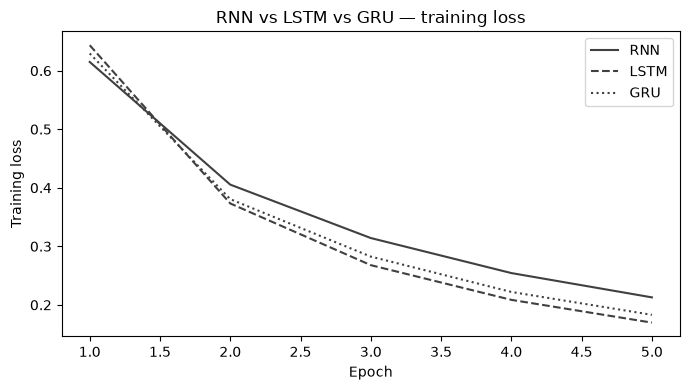

In [10]:
# [RUN] — training curve comparison

fig_arch, ax = plt.subplots(figsize=(7, 4))
for label, losses, style in [
    ('RNN',  rnn_losses,   '-'),
    ('LSTM', lstm1_losses, '--'),
    ('GRU',  gru_losses,   ':'),
]:
    ax.plot(range(1, len(losses)+1), losses, linestyle=style,
            color='#404040', label=label)
ax.set_xlabel('Epoch')
ax.set_ylabel('Training loss')
ax.set_title('RNN vs LSTM vs GRU — training loss')
ax.legend()
plt.tight_layout()
plt.show()

### 2.3 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** The LSTM and GRU both outperform the plain RNN on this task. Explain the specific gating mechanism in each that prevents gradients from vanishing — do not just say "gates help." Identify the one structural difference between LSTM and GRU gating that makes the GRU computationally cheaper, and explain what it gives up in return.

**Question B:** For a sequence tagging task on relatively short sentences (average length ~15 tokens), the plain RNN does not fail as catastrophically as it would on very long sequences. Explain why short sequences partially mitigate the vanishing gradient problem, and describe a realistic NLP task where you would expect the gap between RNN and LSTM/GRU to be much larger.

**Your reflection:**

**A.** In a plain RNN the gradient reaching $k$ steps back is a product of $k$ Jacobians $\mathrm{diag}(1 - h_t^2)\,W$, which shrinks geometrically when their norms are below 1. The LSTM's additive cell update $c_t = f_t \odot c_{t-1} + i_t \odot \tilde{c}_t$ gives $\partial c_t / \partial c_{t-1} = \mathrm{diag}(f_t)$, with no weight matrix or tanh derivative, so a forget gate near 1 passes the error back almost intact; the GRU's interpolation $h_t = (1 - z_t) \odot h_{t-1} + z_t \odot \tilde{h}_t$ opens the same path through $\mathrm{diag}(1 - z_t)$. The GRU is cheaper because one update gate both forgets and writes, with no separate cell state or output gate (176,640 recurrent parameters against 235,520), so it cannot keep old content and add new content independently, a loss that did not show here (F1 0.6900 against 0.6906).

**B.** The vanishing factor compounds once per time step, and CoNLL-2003 sentences are short (mean 14.50 tokens) with mostly local evidence, such as *Mr.* before a name, that the bidirectional layer reaches within a few steps. A product of a few Jacobians has not yet decayed to nothing, so the RNN still reaches 0.6184 F1, 0.0722 below the LSTM's 0.6906. The gap should be far larger in document-level sentiment classification with a unidirectional RNN reading a 400-token review, where the error signal from the final state must cross hundreds of steps to reach a decisive early phrase.

---

## Part 3 — Teacher Forcing (20 points)

Sequence-to-sequence models use an encoder to read an input sequence and a decoder to generate an output sequence one token at a time. During training, the decoder at step $t$ needs an input — the previous output token. There are two choices:

- **Teacher forcing (TF=1.0):** Always feed the *ground-truth* token from the target sequence. Training is stable because the decoder always gets correct context.
- **Free running (TF=0.0):** Always feed the *model's own prediction* from the previous step. More realistic at inference time, but error accumulation makes early training noisy.
- **Scheduled teacher forcing:** Interpolate between the two — feed ground truth with probability $p$ and the model's own prediction with probability $1-p$.

The tension: a model trained with full teacher forcing has never seen its own mistakes during training and may be brittle when it makes an error at inference time.

We demonstrate this on a **character-level word reversal** task: the model reads a short sequence of characters and must output them in reverse order. This is a clean seq2seq task that trains in minutes on CPU and makes the teacher forcing effect clearly visible.

### 3.1 — Reversal dataset

In [11]:
# [DO NOT MODIFY] — reversal dataset

# Character vocabulary
CHARS = list('abcdefghijklmnopqrstuvwxyz')
SOS_TOKEN, EOS_TOKEN, PAD_TOKEN_SEQ2SEQ = '<SOS>', '<EOS>', '<PAD>'
CHAR_VOCAB = [PAD_TOKEN_SEQ2SEQ, SOS_TOKEN, EOS_TOKEN] + CHARS
CHAR2IDX   = {c: i for i, c in enumerate(CHAR_VOCAB)}
IDX2CHAR   = {i: c for c, i in CHAR2IDX.items()}
SEQ_VOCAB_SIZE = len(CHAR_VOCAB)
SOS_IDX = CHAR2IDX[SOS_TOKEN]
EOS_IDX = CHAR2IDX[EOS_TOKEN]

def make_reversal_data(n_samples=3000, min_len=4, max_len=10, seed=42):
    """Generate (source, target) pairs for character reversal.

    Source: random lowercase character sequence.
    Target: SOS + reversed source + EOS.

    Args:
        n_samples (int): Number of samples to generate.
        min_len   (int): Minimum source sequence length.
        max_len   (int): Maximum source sequence length.
        seed      (int): Random seed for reproducibility.

    Returns:
        list[tuple[list[int], list[int]]]:
            Each element is (source_indices, target_indices).
    """
    rng = random.Random(seed)
    data = []
    for _ in range(n_samples):
        length = rng.randint(min_len, max_len)
        src = [rng.choice(CHARS) for _ in range(length)]
        tgt = [SOS_TOKEN] + src[::-1] + [EOS_TOKEN]
        data.append(([CHAR2IDX[c] for c in src],
                     [CHAR2IDX[c] for c in tgt]))
    return data

reversal_data  = make_reversal_data(3000)
reversal_test  = make_reversal_data(500, seed=99)
print(f"Reversal dataset: {len(reversal_data)} train, {len(reversal_test)} test")

src_ex, tgt_ex = reversal_data[0]
print(f"Example source: {''.join(IDX2CHAR[i] for i in src_ex)}")
print(f"Example target: {''.join(IDX2CHAR[i] for i in tgt_ex)}")

Reversal dataset: 3000 train, 500 test
Example source: daxihhexd
Example target: <SOS>dxehhixad<EOS>


### 3.2 — Seq2seq model with configurable teacher forcing

In [12]:
class Seq2SeqReversal(nn.Module):
    """LSTM encoder-decoder for character sequence reversal.

    The encoder reads the source sequence. The decoder generates the
    output token by token, taking either the ground-truth token
    (teacher forcing) or its own previous prediction as input,
    controlled by teacher_forcing_ratio.

    Args:
        vocab_size  (int):   Character vocabulary size.
        embed_dim   (int):   Embedding dimension for encoder and decoder.
        hidden_dim  (int):   LSTM hidden dimension for encoder and decoder.
        pad_idx     (int):   Padding index in the character vocabulary.
    """

    def __init__(self, vocab_size, embed_dim, hidden_dim, pad_idx=0):
        super().__init__()
        require_positive_ints(vocab_size=vocab_size, embed_dim=embed_dim,
                              hidden_dim=hidden_dim)
        self.pad_idx = pad_idx
        # Shared: encoder and decoder read the same character alphabet.
        self.embedding = nn.Embedding(vocab_size, embed_dim,
                                      padding_idx=pad_idx)
        self.encoder = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.decoder = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def encode(self, src):
        """Encode a padded source batch into the decoder's initial state.

        Source lengths are read off the padding, and the batch is packed so
        the state comes from each source's last real character, not from
        trailing pads.

        Args:
            src (torch.LongTensor): Source indices, shape (batch, src_len).

        Returns:
            tuple[torch.Tensor, torch.Tensor]: Final (h, c) of the encoder.
        """
        lengths = (src != self.pad_idx).sum(dim=1)
        _, state = self.encoder(pack_padded_sequence(
            self.embedding(src), lengths.cpu(), batch_first=True,
            enforce_sorted=False))
        return state

    def decode_step(self, inp, state):
        """Run the decoder for one time step.

        Args:
            inp   (torch.LongTensor): Previous token per sequence, shape (batch, 1).
            state (tuple):            Decoder (h, c) from the previous step.

        Returns:
            tuple: (logits of shape (batch, 1, vocab_size), new (h, c)).
        """
        out, state = self.decoder(self.embedding(inp), state)
        return self.fc(out), state

    def forward(self, src, tgt, teacher_forcing_ratio=0.5):
        """Forward pass with configurable teacher forcing.

        Args:
            src (torch.LongTensor): Source indices, shape (batch, src_len).
            tgt (torch.LongTensor): Target indices, shape (batch, tgt_len).
                                    tgt[:, 0] is the SOS token.
            teacher_forcing_ratio (float): Probability in [0, 1] of using
                the ground-truth token as the next decoder input.
                1.0 = full teacher forcing; 0.0 = free running.

        Returns:
            torch.Tensor: Logits, shape (batch, tgt_len-1, vocab_size).
        """
        if not 0.0 <= teacher_forcing_ratio <= 1.0:
            raise ValueError("teacher_forcing_ratio must be in [0, 1], "
                             f"got {teacher_forcing_ratio!r}")
        if src.size(0) != tgt.size(0) or tgt.size(1) < 2:
            raise ValueError("src and tgt need the same batch size, and tgt "
                             "needs SOS plus at least one token")

        state = self.encode(src)
        inp = tgt[:, :1]                                # SOS for every sequence
        outputs = []
        for t in range(1, tgt.size(1)):
            logits, state = self.decode_step(inp, state)
            outputs.append(logits)
            # Each sequence draws its own coin: the gold token with
            # probability teacher_forcing_ratio, else its own greedy guess.
            use_gold = (torch.rand(tgt.size(0), 1, device=tgt.device)
                        < teacher_forcing_ratio)
            inp = torch.where(use_gold, tgt[:, t:t + 1], logits.argmax(dim=-1))
        return torch.cat(outputs, dim=1)

    @torch.no_grad()
    def greedy_decode(self, src, sos_idx, eos_idx, max_len):
        """Free-running greedy decoding with no target sequence.

        Args:
            src     (torch.LongTensor): Source indices, shape (batch, src_len).
            sos_idx (int):              Start-of-sequence index.
            eos_idx (int):              End-of-sequence index.
            max_len (int):              Maximum number of decoding steps.

        Returns:
            torch.LongTensor: Predicted indices, shape (batch, n_steps), where
            n_steps <= max_len; tokens after a sequence's EOS are not meaningful.
        """
        require_positive_ints(max_len=max_len)
        state = self.encode(src)
        inp = torch.full((src.size(0), 1), sos_idx, dtype=torch.long,
                         device=src.device)
        steps = []
        finished = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
        for _ in range(max_len):
            logits, state = self.decode_step(inp, state)
            inp = logits.argmax(dim=-1)                 # (batch, 1)
            steps.append(inp)
            finished |= inp.squeeze(1) == eos_idx
            if finished.all():                          # every sequence stopped
                break
        return torch.cat(steps, dim=1)

### 3.3 — Train with different teacher forcing ratios

In [13]:
def collate_seq2seq(batch):
    """Collate reversal (source, target) pairs into padded batch tensors.

    Args:
        batch (list[tuple[list[int], list[int]]]): (source, target) pairs.

    Returns:
        tuple:
            src_tensor (torch.LongTensor): Shape (batch, max_src_len).
            tgt_tensor (torch.LongTensor): Shape (batch, max_tgt_len).
    """
    pad_idx = CHAR2IDX[PAD_TOKEN_SEQ2SEQ]
    sources, targets = zip(*batch) if batch else ((), ())
    return (pad_sequences(list(sources), pad_idx),
            pad_sequences(list(targets), pad_idx))


def train_seq2seq(teacher_forcing_ratio, n_epochs=30, lr=1e-3,
                  batch_size=128, embed_dim=32, hidden_dim=64, seed=42):
    """Train a Seq2SeqReversal model and return per-epoch losses.

    The reported loss is the per-token cross-entropy under the training
    inputs, so with TF < 1 it includes steps fed the model's own guesses.

    Args:
        teacher_forcing_ratio (float or callable): Fixed TF ratio throughout
            training, or a function epoch_index -> ratio for a schedule.
        n_epochs   (int):   Training epochs.
        lr         (float): Adam learning rate.
        batch_size (int):   Batch size.
        embed_dim  (int):   Embedding dimension.
        hidden_dim (int):   LSTM hidden dimension.
        seed       (int):   Seed for weight init, batch order and TF coins.

    Returns:
        tuple:
            model       (Seq2SeqReversal): Trained model.
            train_losses (list[float]):    Per-epoch training loss.
    """
    require_positive_ints(n_epochs=n_epochs, batch_size=batch_size)
    schedule = (teacher_forcing_ratio if callable(teacher_forcing_ratio)
                else lambda epoch: teacher_forcing_ratio)

    torch.manual_seed(seed)
    pad_idx = CHAR2IDX[PAD_TOKEN_SEQ2SEQ]
    model = Seq2SeqReversal(SEQ_VOCAB_SIZE, embed_dim, hidden_dim,
                            pad_idx=pad_idx).to(DEVICE)
    loader = DataLoader(reversal_data, batch_size=batch_size, shuffle=True,
                        collate_fn=collate_seq2seq)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    # Here index 0 really is <PAD> (the positions after a short target's EOS).
    criterion = nn.CrossEntropyLoss(ignore_index=pad_idx)

    train_losses = []
    for epoch in range(n_epochs):
        ratio = schedule(epoch)
        model.train()
        total_loss, total_tokens = 0.0, 0
        for src, tgt in loader:
            src, tgt = src.to(DEVICE), tgt.to(DEVICE)
            optimizer.zero_grad()
            logits = model(src, tgt, teacher_forcing_ratio=ratio)
            gold = tgt[:, 1:]                   # step t predicts tgt[:, t]
            loss = criterion(logits.reshape(-1, logits.size(-1)),
                             gold.reshape(-1))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            n_tokens = int((gold != pad_idx).sum())
            total_loss += loss.item() * n_tokens
            total_tokens += n_tokens
        train_losses.append(total_loss / total_tokens)
        if epoch == 0 or (epoch + 1) % 10 == 0:
            print(f"  Epoch {epoch + 1:2d}/{n_epochs}  TF={ratio:.2f}  "
                  f"loss={train_losses[-1]:.4f}")
    return model, train_losses


print("Training with full teacher forcing (TF=1.0)...")
model_tf1, losses_tf1 = train_seq2seq(teacher_forcing_ratio=1.0)

print("\nTraining with scheduled teacher forcing (TF=0.5)...")
model_tf5, losses_tf5 = train_seq2seq(teacher_forcing_ratio=0.5)

print("\nTraining with free running (TF=0.0)...")
model_tf0, losses_tf0 = train_seq2seq(teacher_forcing_ratio=0.0)

print(f"\nFinal training losses:")
print(f"  TF=1.0: {losses_tf1[-1]:.4f}")
print(f"  TF=0.5: {losses_tf5[-1]:.4f}")
print(f"  TF=0.0: {losses_tf0[-1]:.4f}")

Training with full teacher forcing (TF=1.0)...


  Epoch  1/30  TF=1.00  loss=3.3219


  Epoch 10/30  TF=1.00  loss=1.3186


  Epoch 20/30  TF=1.00  loss=0.6765


  Epoch 30/30  TF=1.00  loss=0.4602

Training with scheduled teacher forcing (TF=0.5)...


  Epoch  1/30  TF=0.50  loss=3.3114


... (3 outputs left out)

  Epoch  1/30  TF=0.00  loss=3.2770


  Epoch 10/30  TF=0.00  loss=1.9183


  Epoch 20/30  TF=0.00  loss=1.3513


  Epoch 30/30  TF=0.00  loss=0.9575

Final training losses:
  TF=1.0: 0.4602
  TF=0.5: 0.9539
  TF=0.0: 0.9575


In [14]:
def greedy_outputs(model, test_data, eos_idx, max_len=15,
                   sos_idx=SOS_IDX, batch_size=256):
    """Decode a dataset free-running and pair each output with its gold.

    Args:
        model      (Seq2SeqReversal): Trained model.
        test_data  (list[tuple]):     (source, target) index pairs.
        eos_idx    (int):             EOS token index.
        max_len    (int):             Maximum decoding steps.
        sos_idx    (int):             SOS token index.
        batch_size (int):             Sequences decoded per forward pass.

    Returns:
        list[tuple[list[int], list[int]]]: (gold, predicted) per sequence.
        gold is the target without SOS, so it ends with EOS; predicted is
        cut after its first EOS (or left at max_len tokens if none).
    """
    if not test_data:
        raise ValueError("test_data is empty")
    was_training = model.training
    model.eval()
    device = next(model.parameters()).device
    pairs = []
    for start in range(0, len(test_data), batch_size):
        chunk = test_data[start:start + batch_size]
        src, _ = collate_seq2seq(chunk)
        decoded = model.greedy_decode(src.to(device), sos_idx, eos_idx,
                                      max_len).cpu().tolist()
        for (_, tgt), pred in zip(chunk, decoded):
            if eos_idx in pred:
                pred = pred[:pred.index(eos_idx) + 1]
            pairs.append((tgt[1:], pred))
    model.train(was_training)
    return pairs


def evaluate_seq2seq(model, test_data, eos_idx, max_len=15):
    """Evaluate a seq2seq model on the reversal test set.

    Runs inference with teacher_forcing_ratio=0.0 (free running) to
    simulate actual deployment. Returns character-level accuracy and
    exact-sequence accuracy.

    Args:
        model     (Seq2SeqReversal): Trained model.
        test_data (list[tuple]):     (source, target) index pairs.
        eos_idx   (int):             EOS token index.
        max_len   (int):             Maximum decoding steps.

    Returns:
        tuple[float, float]: (char_accuracy, exact_sequence_accuracy)

    Character accuracy compares output and gold (reversed source + EOS)
    position by position over the gold length; positions the model never
    produced count as wrong. Exact accuracy needs the whole output, EOS
    included, to match.
    """
    pairs = greedy_outputs(model, test_data, eos_idx, max_len)
    n_correct = sum(p == g for gold, pred in pairs for p, g in zip(pred, gold))
    n_chars = sum(len(gold) for gold, _ in pairs)
    n_exact = sum(pred == gold for gold, pred in pairs)
    return n_correct / n_chars, n_exact / len(pairs)


# Named output variables
tf1_char_acc, tf1_exact_acc = evaluate_seq2seq(model_tf1, reversal_test, EOS_IDX)
tf5_char_acc, tf5_exact_acc = evaluate_seq2seq(model_tf5, reversal_test, EOS_IDX)
tf0_char_acc, tf0_exact_acc = evaluate_seq2seq(model_tf0, reversal_test, EOS_IDX)

print("Evaluation (free-running inference on test set):")
print(f"{'TF ratio':<10s} {'Char acc':>10s}  {'Exact acc':>10s}")
print("-" * 34)
for label, ca, ea in [
    ("TF=1.0", tf1_char_acc, tf1_exact_acc),
    ("TF=0.5", tf5_char_acc, tf5_exact_acc),
    ("TF=0.0", tf0_char_acc, tf0_exact_acc),
]:
    print(f"{label:<10s} {ca:>10.4f}  {ea:>10.4f}")

Evaluation (free-running inference on test set):
TF ratio     Char acc   Exact acc
----------------------------------
TF=1.0         0.6483      0.4300
TF=0.5         0.5730      0.2140
TF=0.0         0.6234      0.1520


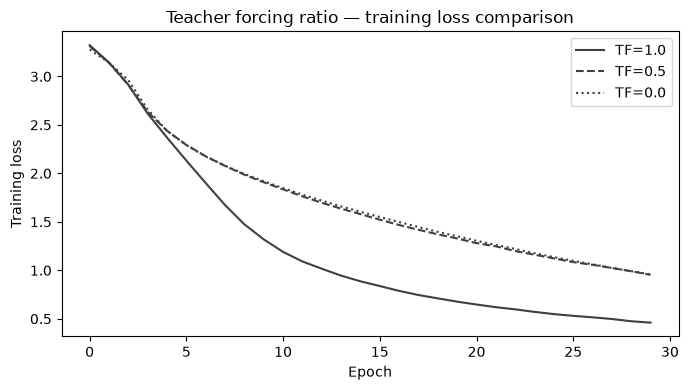

In [15]:
# [RUN] — training curve comparison

fig_tf, ax = plt.subplots(figsize=(7, 4))
for label, losses, style in [
    ('TF=1.0', losses_tf1, '-'),
    ('TF=0.5', losses_tf5, '--'),
    ('TF=0.0', losses_tf0, ':'),
]:
    ax.plot(losses, linestyle=style, color='#404040', label=label)
ax.set_xlabel('Epoch')
ax.set_ylabel('Training loss')
ax.set_title('Teacher forcing ratio — training loss comparison')
ax.legend()
plt.tight_layout()
plt.show()

### 3.4 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** The training loss curves almost certainly show TF=1.0 converging fastest. Yet when evaluated with free-running inference, TF=1.0 may perform worse than TF=0.5. Explain the mechanism that causes this gap: what specific mismatch between training and inference does full teacher forcing create, and what is it called in the sequence modeling literature?

**Question B:** Scheduled teacher forcing (TF=0.5) is a middle ground, but the schedule is fixed throughout training. Describe a *dynamic* teacher forcing schedule that would be more principled — one that changes the ratio over the course of training — and explain why that schedule better matches the model's actual capability at each stage of learning.

**Your reflection:**

**A.** Full teacher forcing trains the decoder only on gold prefixes, but at inference it consumes its own outputs, so one wrong character leads it into states never seen in training and errors compound; this train–test mismatch is **exposure bias** (Ranzato et al., 2016). In Part 5.4, TF=1.0's character accuracy falls from 0.8489 with gold prefixes to 0.6483 free-running (a gap of 0.2005, against 0.0524 for TF=0.0), and after its first error it gets only 0.3130 of the remaining characters right, the weakest recovery of the three models. It still had the best exact accuracy here (0.4300 against 0.2140 for TF=0.5) because its cleaner training signal delays the first error, so exposure bias lowered its ceiling without reversing the ranking.

**B.** A more principled option is scheduled sampling (Bengio et al., 2015) driven by competence rather than the epoch counter: after each epoch, set the probability of feeding the decoder its own prediction to its free-running character accuracy on a validation set, so training starts near TF=1.0. Early predictions are close to random and would only add noise, while later ones resemble what inference produces, so the decoder practises recovering from its own mistakes once that practice is informative. Part 5.5 shows why the clock is the wrong signal: a time-based inverse-sigmoid decay cut the ratio to 0.37 by epoch 20 while training loss was still 1.4308, and it finished with the lowest exact accuracy (0.0840).

---

## Part 4 — Failure Pattern Diagnosis (18 points)

A macro-averaged F1 score tells you how well the model performs on average, but it hides systematic errors. Real-world NLP debugging requires understanding *where* and *why* a model fails — not just that it scores 0.72 instead of 0.85.

In this part you will decompose your LSTM tagger's errors into three categories and use those patterns to justify specific improvements.

### 4.1 — Per-entity-type F1

In [16]:
def per_type_f1(all_true_tags, all_pred_tags):
    """Compute per-entity-type precision, recall, and F1.

    Aggregates span-level TP, FP, FN across all sentences, then computes
    per-type metrics.

    Args:
        all_true_tags (list[list[str]]): Gold BIO sequences.
        all_pred_tags (list[list[str]]): Predicted BIO sequences.

    Returns:
        dict[str, dict]: Maps entity type to
            {'precision': float, 'recall': float, 'f1': float,
             'support': int}
        support is the number of gold spans of that type.
    """
    if len(all_true_tags) != len(all_pred_tags):
        raise ValueError(f"{len(all_true_tags)} gold sentences but "
                         f"{len(all_pred_tags)} predicted")
    n_gold, n_pred, n_correct = Counter(), Counter(), Counter()
    for true_tags, pred_tags in zip(all_true_tags, all_pred_tags):
        if len(true_tags) != len(pred_tags):
            raise ValueError("gold and predicted sentences differ in length")
        gold, pred = bio_to_spans(true_tags), bio_to_spans(pred_tags)
        n_gold.update(etype for etype, _, _ in gold)
        n_pred.update(etype for etype, _, _ in pred)
        n_correct.update(etype for etype, _, _ in gold & pred)

    results = {}
    for etype in sorted(set(n_gold) | set(n_pred)):
        precision, recall, f1 = precision_recall_f1(
            n_correct[etype], n_pred[etype], n_gold[etype])
        results[etype] = {'precision': precision, 'recall': recall,
                          'f1': f1, 'support': n_gold[etype]}
    return results


def get_predictions(model, loader, ner_tags, device):
    """Collect all gold and predicted BIO tag sequences from a data loader.

    Args:
        model    (nn.Module):   Trained tagger.
        loader   (DataLoader):  Data loader (test or validation).
        ner_tags (list[str]):   Tag index → BIO string mapping.
        device   (torch.device):

    Returns:
        tuple[list[list[str]], list[list[str]]]:
            (all_true_tags, all_pred_tags) — one list per sentence,
            padding positions excluded.
    """
    return logits_to_tags(collect_logits(model, loader, device), ner_tags)


all_true, all_pred = get_predictions(lstm_model, test_loader, NER_TAGS, DEVICE)
type_results = per_type_f1(all_true, all_pred)

print(f"{'Entity type':<15s} {'P':>7s}  {'R':>7s}  {'F1':>7s}  {'Support':>9s}")
print("-" * 50)
for etype, scores in sorted(type_results.items(), key=lambda x: -x[1]['f1']):
    print(f"{etype:<15s} {scores['precision']:>7.4f}  "
          f"{scores['recall']:>7.4f}  {scores['f1']:>7.4f}  "
          f"{scores.get('support',0):>9d}")

Entity type           P        R       F1    Support
--------------------------------------------------
LOC              0.7764   0.7746   0.7755       1668
PER              0.7912   0.6797   0.7312       1617
ORG              0.7628   0.5906   0.6658       1661
MISC             0.7714   0.5527   0.6440        702


### 4.2 — BIO violation analysis

In [17]:
def count_bio_violations(tag_sequences):
    """Count positions where an I-tag follows an incompatible tag.

    An I-X tag is a violation if it does not follow B-X or I-X of the
    same entity type X. This indicates the model produced structurally
    invalid BIO sequences.

    Args:
        tag_sequences (list[list[str]]): Predicted BIO sequences.

    Returns:
        tuple[int, int]: (n_violations, total_I_tags)
    """
    n_violations = n_i_tags = 0
    for tags in tag_sequences:
        prev = 'O'                          # a sentence start behaves like O
        for tag in tags:
            if tag.startswith('I-'):
                n_i_tags += 1
                etype = tag[2:]
                if prev not in (f'B-{etype}', f'I-{etype}'):
                    n_violations += 1
            prev = tag
    return n_violations, n_i_tags


def count_boundary_errors(all_true, all_pred):
    """Count off-by-one span boundary errors.

    A boundary error occurs when a predicted span has the correct entity
    type and overlaps with a gold span, but the start or end index
    differs by exactly 1. Returns the count of such near-miss pairs.

    Args:
        all_true (list[list[str]]): Gold BIO sequences.
        all_pred (list[list[str]]): Predicted BIO sequences.

    Returns:
        int: Number of boundary error pairs found.

    Read here as: same type, the spans overlap, they are not identical, and
    neither boundary is more than one token off (so at least one of start
    and end differs by exactly 1).
    """
    if len(all_true) != len(all_pred):
        raise ValueError(f"{len(all_true)} gold sentences but "
                         f"{len(all_pred)} predicted")
    n_errors = 0
    for true_tags, pred_tags in zip(all_true, all_pred):
        gold, pred = bio_to_spans(true_tags), bio_to_spans(pred_tags)
        # Exact matches are not errors, so compare only the leftovers.
        for g_type, g_start, g_end in gold - pred:
            for p_type, p_start, p_end in pred - gold:
                overlaps = p_start <= g_end and g_start <= p_end
                if (p_type == g_type and overlaps
                        and abs(p_start - g_start) <= 1
                        and abs(p_end - g_end) <= 1):
                    n_errors += 1
    return n_errors


n_viols, n_i_tags = count_bio_violations(all_pred)
n_boundary = count_boundary_errors(all_true, all_pred)

print(f"BIO violations:   {n_viols:,} / {n_i_tags:,} I-tags "
      f"({100*n_viols/max(n_i_tags,1):.1f}%)")
print(f"Boundary errors:  {n_boundary:,} near-miss spans")

BIO violations:   191 / 2,326 I-tags (8.2%)
Boundary errors:  229 near-miss spans


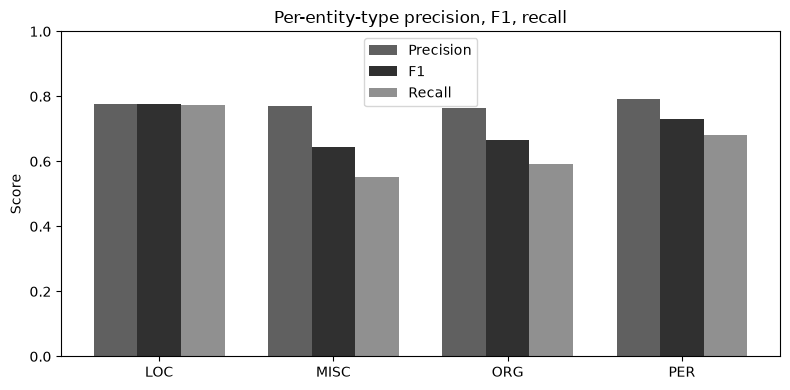

In [18]:
# [RUN] — per-type F1 bar chart

fig_types, ax = plt.subplots(figsize=(8, 4))
etypes = [e for e in type_results if e != 'O']
f1s    = [type_results[e]['f1'] for e in etypes]
precs  = [type_results[e]['precision'] for e in etypes]
recs   = [type_results[e]['recall'] for e in etypes]

x = np.arange(len(etypes))
w = 0.25
ax.bar(x - w, precs, w, color='#606060', label='Precision')
ax.bar(x,     f1s,   w, color='#303030', label='F1')
ax.bar(x + w, recs,  w, color='#909090', label='Recall')
ax.set_xticks(x); ax.set_xticklabels(etypes)
ax.set_ylabel('Score'); ax.set_ylim(0, 1)
ax.set_title('Per-entity-type precision, F1, recall')
ax.legend(); plt.tight_layout(); plt.show()

### 4.3 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** Identify the entity type with the lowest F1 score. Explain *why* that type is harder to tag than the others — think about how that entity type appears in text: is it ambiguous, rare, syntactically unpredictable? What does a higher false-positive or false-negative rate for that type tell you about what the model has learned?

**Question B:** Choose one of the three error categories you measured — BIO violations, boundary errors, or a low-F1 entity type — and propose a specific architectural or data modification that would directly address it. Justify your proposal: explain the mechanism by which that modification reduces the specific error type you chose.

**Your reflection:**

**A.** MISC has the lowest F1 (0.6440), and its weakness is recall (0.5527) rather than precision (0.7714): 208 of its 314 missed spans had no overlapping prediction at all, so the model fails to notice MISC entities rather than mislabelling them (Part 5.6). MISC is a catch-all with no shared syntactic or orthographic signature (demonyms such as *Lebanese*, events such as *World Cup*, political labels such as *Conservative*) and the rarest type (3,438 training spans against 6,321 to 7,140), and 193 of the 314 missed spans contain an unknown word against 12 of the 388 found. High precision with low recall shows the model has memorised frequent MISC strings rather than learned what makes a span MISC: it finds *Italian* but misses *Italians*.

**B.** For the 191 BIO violations (8.2% of predicted I-tags), I would add a linear-chain CRF layer to the BiLSTM, which scores every tag-to-tag transition and decodes the whole sentence with Viterbi. The softmax picks each tag independently, so nothing stops O followed by I-ORG; a CRF learns a strongly negative score for that transition, so Viterbi replaces the stray I-tag, which `bio_to_spans` discards, with a B-tag that recovers the entity or with an O. Part 5.7 applies the hard-constraint version to the existing scores without retraining: violations fall from 191 to 0 and macro F1 rises from 0.7224 to 0.7261, but boundary errors go from 229 to 234, so larger gains need transition scores trained jointly with the encoder.

---

## Part 5 — Supporting checks (ungraded)

The reflections above cite exact values printed in this part. These cells only read the graded variables and models; none of them is reassigned.

### 5.1 — Span counts, corpus-level scores, and token accuracy

In [19]:
def span_totals(all_true, all_pred):
    """Corpus-wide counts of correct, predicted and gold spans.

    Args:
        all_true (list[list[str]]): Gold BIO sequences.
        all_pred (list[list[str]]): Predicted BIO sequences.

    Returns:
        tuple[int, int, int]: (n_correct, n_pred, n_gold)
    """
    n_correct = n_pred = n_gold = 0
    for true_tags, pred_tags in zip(all_true, all_pred):
        gold, pred = bio_to_spans(true_tags), bio_to_spans(pred_tags)
        n_correct += len(gold & pred)
        n_pred += len(pred)
        n_gold += len(gold)
    return n_correct, n_pred, n_gold


def token_accuracy(all_true, all_pred):
    """Fraction of tokens whose predicted tag equals the gold tag.

    Args:
        all_true (list[list[str]]): Gold BIO sequences.
        all_pred (list[list[str]]): Predicted BIO sequences.

    Returns:
        float: Correct tokens over all tokens, pooled across sentences.
    """
    pairs = [(t, p) for ts, ps in zip(all_true, all_pred) for t, p in zip(ts, ps)]
    return sum(t == p for t, p in pairs) / len(pairs)


n_correct, n_pred, n_gold = span_totals(all_true, all_pred)
micro_p, micro_r, micro_f1 = precision_recall_f1(n_correct, n_pred, n_gold)
all_o = [['O'] * len(tags) for tags in all_true]
no_entity = [i for i, tags in enumerate(all_true) if not bio_to_spans(tags)]
no_entity_clean = sum(not bio_to_spans(all_pred[i]) for i in no_entity)

print("BiLSTM (Part 1) on the test set")
print(f"  Macro over sentences:  P={lstm_precision:.4f}  R={lstm_recall:.4f}  F1={lstm_f1:.4f}")
print(f"  Micro over corpus:     P={micro_p:.4f}  R={micro_r:.4f}  F1={micro_f1:.4f}")
print(f"  Gold spans {n_gold:,}, predicted {n_pred:,}, correct {n_correct:,}")
print(f"  False positives {n_pred - n_correct:,}, false negatives {n_gold - n_correct:,}")
print(f"  Sentences with no gold entity: {len(no_entity):,} of {len(all_true):,}, "
      f"{no_entity_clean:,} of them predicted with no entity (score 1.0)")
print()
print(f"Token accuracy, BiLSTM:          {token_accuracy(all_true, all_pred):.4f}")
print(f"Token accuracy, all-O baseline:  {token_accuracy(all_true, all_o):.4f}  "
      f"(span F1 {np.mean([span_f1(t, p)[2] for t, p in zip(all_true, all_o)]):.4f} macro, "
      f"{precision_recall_f1(*span_totals(all_true, all_o))[2]:.4f} micro)")

BiLSTM (Part 1) on the test set
  Macro over sentences:  P=0.7455  R=0.7145  F1=0.7224
  Micro over corpus:     P=0.7765  R=0.6657  F1=0.7169
  Gold spans 5,648, predicted 4,842, correct 3,760
  False positives 1,082, false negatives 1,888
  Sentences with no gold entity: 697 of 3,453, 600 of them predicted with no entity (score 1.0)

Token accuracy, BiLSTM:          0.9387
Token accuracy, all-O baseline:  0.8253  (span F1 0.2019 macro, 0.0000 micro)


In [20]:
test_tokens = conll['test']['tokens']        # test_loader is unshuffled: same order

def near_miss_spans(all_true, all_pred):
    """Missed multi-token gold spans whose tokens are mostly tagged correctly.

    Token accuracy credits most of each such span; span F1 credits none.

    Args:
        all_true (list[list[str]]): Gold BIO sequences.
        all_pred (list[list[str]]): Predicted BIO sequences.

    Returns:
        list[tuple[int, tuple]]: (sentence index, gold span) pairs.
    """
    hits = []
    for i, (true_tags, pred_tags) in enumerate(zip(all_true, all_pred)):
        for span in bio_to_spans(true_tags) - bio_to_spans(pred_tags):
            _, start, end = span
            n_ok = sum(true_tags[k] == pred_tags[k] for k in range(start, end + 1))
            if end > start and 2 * n_ok >= end - start + 1:
                hits.append((i, span))
    return hits


near = near_miss_spans(all_true, all_pred)
opened_with_i = sum(all_pred[i][start] == f'I-{etype}'
                    for i, (etype, start, _) in near)
print(f"Missed multi-token spans with at least half their tokens tagged "
      f"correctly: {len(near):,} of {n_gold - n_correct:,} missed spans")
print(f"  of which the prediction opens the span with I-X instead of B-X: {opened_with_i:,}")

i, (etype, start, end) = next((i, s) for i, s in near if s[2] - s[1] >= 2)
print(f"\nExample (sentence {i}, gold {etype} span {start}-{end}):")
for k in range(max(0, start - 1), min(len(all_true[i]), end + 2)):
    print(f"  {test_tokens[i][k]:<14s} gold {all_true[i][k]:<7s} pred {all_pred[i][k]}")

Missed multi-token spans with at least half their tokens tagged correctly: 220 of 1,888 missed spans
  of which the prediction opens the span with I-X instead of B-X: 25

Example (sentence 137, gold MISC span 2-4):
  -              gold O       pred O
  ENGLISH        gold B-MISC  pred B-MISC
  F.A.           gold I-MISC  pred I-MISC
  CUP            gold I-MISC  pred I-MISC
  SECOND         gold O       pred I-MISC


### 5.2 — Unknown words and recall

In [21]:
def span_has_unk(tokens, span):
    """Check whether a span contains a word that build_vocab left out.

    Args:
        tokens (list[str]): The sentence's tokens.
        span   (tuple):     (entity_type, start, end), end inclusive.

    Returns:
        bool: True if any token in the span maps to <UNK>.
    """
    _, start, end = span
    return any(tok not in WORD2IDX for tok in tokens[start:end + 1])


tok_counts = Counter()
for tokens, tags in zip(test_tokens, all_true):
    for tok, tag in zip(tokens, tags):
        kind = 'O' if tag == 'O' else 'entity'
        tok_counts[kind] += 1
        tok_counts[kind + '_unk'] += tok not in WORD2IDX

found = Counter()
for tokens, true_tags, pred_tags in zip(test_tokens, all_true, all_pred):
    pred = bio_to_spans(pred_tags)
    for span in bio_to_spans(true_tags):
        group = 'with UNK' if span_has_unk(tokens, span) else 'all known'
        found[group + ' total'] += 1
        found[group + ' found'] += span in pred

for kind in ('O', 'entity'):
    print(f"UNK rate among {kind:>6} tokens: "
          f"{tok_counts[kind + '_unk'] / tok_counts[kind]:.4f}  "
          f"({tok_counts[kind + '_unk']:,} of {tok_counts[kind]:,})")
print()
for group in ('all known', 'with UNK'):
    total, hit = found[group + ' total'], found[group + ' found']
    print(f"Gold spans {group:<10}: {total:>5,}  recall {hit / total:.4f}")

UNK rate among      O tokens: 0.1086  (4,160 of 38,323)
UNK rate among entity tokens: 0.3786  (3,071 of 8,112)

Gold spans all known : 3,224  recall 0.7788
Gold spans with UNK  : 2,424  recall 0.5153


### 5.3 — Recurrent-unit sizes and sentence lengths (Part 2)

In [22]:
print("Recurrent-layer parameters (one bidirectional layer, "
      f"embed {EMBED_DIM}, hidden {HIDDEN_DIM}):")
for rnn_type in RNN_CLASSES:
    tagger = GenericRNNTagger(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, N_TAGS,
                              rnn_type=rnn_type)
    n_rnn = sum(p.numel() for p in tagger.rnn.parameters())
    print(f"  {rnn_type.upper():<5} {n_rnn:>9,}")

train_lengths = np.array([len(t) for t in conll['train']['tokens']])
print()
print(f"Train sentence length: mean {train_lengths.mean():.2f}, "
      f"median {np.median(train_lengths):.0f}, "
      f"90th pct {np.percentile(train_lengths, 90):.0f}, max {train_lengths.max()}")
print(f"Share of sentences longer than 40 tokens: {(train_lengths > 40).mean():.4f}")

Recurrent-layer parameters (one bidirectional layer, embed 100, hidden 128):
  RNN      58,880
  LSTM    235,520
  GRU     176,640

Train sentence length: mean 14.50, median 10, 90th pct 32, max 113
Share of sentences longer than 40 tokens: 0.0296


### 5.4 — Exposure bias diagnostics (Part 3)

Teacher-forced accuracy feeds the decoder the gold prefix at every step; free-running accuracy (the graded metric) feeds it its own guesses. The gap between the two is the cost of conditioning on the model's own outputs. The second table splits free-running positions into those up to and including the first wrong character and those after it.

In [23]:
def teacher_forced_char_accuracy(model, test_data):
    """Character accuracy when the decoder always receives the gold prefix.

    Args:
        model     (Seq2SeqReversal): Trained model.
        test_data (list[tuple]):     (source, target) index pairs.

    Returns:
        float: Share of gold output positions (EOS included) predicted correctly.
    """
    was_training = model.training
    model.eval()
    src, tgt = collate_seq2seq(test_data)
    src, tgt = src.to(DEVICE), tgt.to(DEVICE)
    with torch.no_grad():
        pred = model(src, tgt, teacher_forcing_ratio=1.0).argmax(dim=-1)
    model.train(was_training)
    gold = tgt[:, 1:]
    real = gold != CHAR2IDX[PAD_TOKEN_SEQ2SEQ]
    return float(((pred == gold) & real).sum() / real.sum())


def accuracy_around_first_error(pairs):
    """Free-running accuracy before vs. after each sequence's first error.

    Args:
        pairs (list[tuple]): (gold, predicted) pairs from greedy_outputs.

    Returns:
        tuple[float, float, int]: (accuracy at positions up to and including
        the first error, accuracy at positions after it, positions after it).
        A sequence with no error contributes only to the first figure.
    """
    before, after = [], []
    for gold, pred in pairs:
        seen_error = False
        for k, g in enumerate(gold):
            ok = k < len(pred) and pred[k] == g
            (after if seen_error else before).append(ok)
            seen_error |= not ok
    return np.mean(before), np.mean(after), len(after)


tf_models = {'TF=1.0': model_tf1, 'TF=0.5': model_tf5, 'TF=0.0': model_tf0}
print(f"{'Model':<8s} {'Teacher-forced':>15s} {'Free-running':>13s} {'Gap':>8s}")
for label, model in tf_models.items():
    forced = teacher_forced_char_accuracy(model, reversal_test)
    free, _ = evaluate_seq2seq(model, reversal_test, EOS_IDX)
    print(f"{label:<8s} {forced:>15.4f} {free:>13.4f} {forced - free:>8.4f}")

print()
print(f"{'Model':<8s} {'Acc before 1st error':>21s} {'Acc after 1st error':>20s} {'(positions)':>12s}")
for label, model in tf_models.items():
    acc_before, acc_after, n_after = accuracy_around_first_error(
        greedy_outputs(model, reversal_test, EOS_IDX))
    print(f"{label:<8s} {acc_before:>21.4f} {acc_after:>20.4f} {n_after:>12,}")

Model     Teacher-forced  Free-running      Gap
TF=1.0            0.8489        0.6483   0.2005


TF=0.5            0.7308        0.5730   0.1578


TF=0.0            0.6757        0.6234   0.0524

Model     Acc before 1st error  Acc after 1st error  (positions)


TF=1.0                  0.8808               0.3130        1,658
TF=0.5                  0.7576               0.4498        2,428
TF=0.0                  0.7207               0.5650        2,531


### 5.5 — A decaying teacher-forcing schedule (Part 3, Question B)

Scheduled sampling (Bengio et al., 2015) starts near full teacher forcing and lowers the ratio as training proceeds. This run uses their inverse-sigmoid decay, $\epsilon_i = k / (k + e^{i/k})$ with $i$ the epoch index and $k = 7.5$, which puts the halfway point ($\epsilon = 0.5$) near epoch 15 of 30. Everything else matches Part 3.

In [24]:
K_DECAY = 7.5

def inverse_sigmoid_tf(epoch, k=K_DECAY):
    """Teacher-forcing ratio for an epoch under inverse-sigmoid decay.

    Args:
        epoch (int):   Zero-based epoch index.
        k     (float): Decay constant; the ratio crosses 0.5 at epoch k ln k.

    Returns:
        float: k / (k + exp(epoch / k)), in (0, 1).
    """
    return k / (k + math.exp(epoch / k))


print("Training with inverse-sigmoid scheduled teacher forcing...")
model_sched, losses_sched = train_seq2seq(teacher_forcing_ratio=inverse_sigmoid_tf)
sched_char_acc, sched_exact_acc = evaluate_seq2seq(model_sched, reversal_test, EOS_IDX)

print()
print(f"{'TF ratio':<14s} {'Char acc':>10s}  {'Exact acc':>10s}")
for label, ca, ea in [("TF=1.0", tf1_char_acc, tf1_exact_acc),
                      ("TF=0.5", tf5_char_acc, tf5_exact_acc),
                      ("TF=0.0", tf0_char_acc, tf0_exact_acc),
                      ("scheduled", sched_char_acc, sched_exact_acc)]:
    print(f"{label:<14s} {ca:>10.4f}  {ea:>10.4f}")

Training with inverse-sigmoid scheduled teacher forcing...


  Epoch  1/30  TF=0.88  loss=3.3233


  Epoch 10/30  TF=0.69  loss=1.8345


  Epoch 20/30  TF=0.37  loss=1.4308


  Epoch 30/30  TF=0.14  loss=1.1632

TF ratio         Char acc   Exact acc
TF=1.0             0.6483      0.4300
TF=0.5             0.5730      0.2140
TF=0.0             0.6234      0.1520
scheduled          0.5248      0.0840


### 5.6 — Where the weakest entity type goes wrong (Part 4, Question A)

In [25]:
def classify_span_errors(all_true, all_pred, etype):
    """Explain each missed gold span and each false-positive span of one type.

    Args:
        all_true (list[list[str]]): Gold BIO sequences.
        all_pred (list[list[str]]): Predicted BIO sequences.
        etype    (str):             Entity type to inspect, e.g. 'MISC'.

    Returns:
        tuple[Counter, Counter]: (missed, false_pos). Keys say what sits on
        the other side: 'tagged <TYPE>' (same boundaries, other type),
        'boundary' (overlapping, same type, other boundaries), 'overlap,
        other type', or 'nothing' (no overlapping span at all).
    """
    def explain(span, others):
        """Return the category key (see Returns above) for one unmatched span.

        Args:
            span   (tuple): The unmatched (type, start, end) span.
            others (set):   Spans from the other side: predicted spans for a
                            missed gold span, gold spans for a false positive.
        """
        s_type, s_start, s_end = span
        overlapping = [o for o in others if o[1] <= s_end and s_start <= o[2]]
        same_bounds = [o for o in overlapping if o[1:] == span[1:]]
        if same_bounds:
            return f"tagged {same_bounds[0][0]}"
        if any(o[0] == s_type for o in overlapping):
            return 'boundary'
        return 'overlap, other type' if overlapping else 'nothing'

    missed, false_pos = Counter(), Counter()
    for true_tags, pred_tags in zip(all_true, all_pred):
        gold, pred = bio_to_spans(true_tags), bio_to_spans(pred_tags)
        for span in gold - pred:
            if span[0] == etype:
                missed[explain(span, pred)] += 1
        for span in pred - gold:
            if span[0] == etype:
                false_pos[explain(span, gold)] += 1
    return missed, false_pos


train_spans = Counter(etype for tags in conll['train']['ner_tags']
                      for etype, _, _ in bio_to_spans([NER_TAGS[i] for i in tags]))
print("Training spans per type:", dict(sorted(train_spans.items())))

weakest = min(type_results, key=lambda e: type_results[e]['f1'])
missed, false_pos = classify_span_errors(all_true, all_pred, weakest)
print(f"\nWeakest type: {weakest}  (F1 {type_results[weakest]['f1']:.4f})")
print(f"  Missed gold {weakest} spans ({sum(missed.values())}): what the model predicted there")
for reason, n in missed.most_common():
    print(f"    {reason:<22s} {n:>4d}")
print(f"  False-positive {weakest} spans ({sum(false_pos.values())}): what the gold has there")
for reason, n in false_pos.most_common():
    print(f"    {reason:<22s} {n:>4d}")

# Surface forms of the weakest type: what the model finds vs. what it misses.
found_text, missed_text = Counter(), Counter()
found_unk = missed_unk = 0
for tokens, true_tags, pred_tags in zip(test_tokens, all_true, all_pred):
    pred = bio_to_spans(pred_tags)
    for span in bio_to_spans(true_tags):
        if span[0] != weakest:
            continue
        text = ' '.join(tokens[span[1]:span[2] + 1])
        if span in pred:
            found_text[text] += 1
            found_unk += span_has_unk(tokens, span)
        else:
            missed_text[text] += 1
            missed_unk += span_has_unk(tokens, span)

print(f"\n  {weakest} spans containing an UNK token: found {found_unk} of "
      f"{sum(found_text.values())}, missed {missed_unk} of {sum(missed_text.values())}")
print(f"  Most frequent found:  {', '.join(t for t, _ in found_text.most_common(10))}")
print(f"  Most frequent missed: {', '.join(t for t, _ in missed_text.most_common(10))}")

Training spans per type: {'LOC': 7140, 'MISC': 3438, 'ORG': 6321, 'PER': 6600}

Weakest type: MISC  (F1 0.6440)
  Missed gold MISC spans (314): what the model predicted there
    nothing                 208
    boundary                 37
    overlap, other type      26
    tagged ORG               18
    tagged LOC               15
    tagged PER               10
  False-positive MISC spans (115): what the gold has there
    boundary                 37
    nothing                  31
    overlap, other type      21
    tagged ORG               17
    tagged LOC                8
    tagged PER                1

  MISC spans containing an UNK token: found 12 of 388, missed 193 of 314
  Most frequent found:  World Cup, European, French, German, Italian, Australian, GMT, Swiss, Polish, British
  Most frequent missed: Internet, Lebanese, Italians, trans-Atlantic, Conservative, Hindu, World Cup, Mexican, Moroccan, BILO


### 5.7 — BIO-constrained decoding (Part 4, Question B)

A CRF output layer scores tag transitions and decodes with Viterbi. The cheapest version of that idea needs no retraining: keep the BiLSTM's per-token scores, forbid the transitions BIO does not allow (`I-X` only after `B-X` or `I-X`, and never at the start), and pick the best valid sequence with Viterbi. This isolates how much of the error is structural.

In [26]:
def bio_transition_mask(ner_tags):
    """Allowed BIO transitions as a boolean matrix allowed[prev, curr].

    Args:
        ner_tags (list[str]): Tag index → BIO string mapping.

    Returns:
        tuple[np.ndarray, np.ndarray]: (allowed, shape (n, n); can_start,
        shape (n,)). I-X may only follow B-X or I-X and may not start.
    """
    n = len(ner_tags)
    allowed = np.ones((n, n), dtype=bool)
    can_start = np.ones(n, dtype=bool)
    for j, curr in enumerate(ner_tags):
        if curr.startswith('I-'):
            etype = curr[2:]
            can_start[j] = False
            allowed[:, j] = [prev in (f'B-{etype}', f'I-{etype}') for prev in ner_tags]
    return allowed, can_start


def constrained_viterbi(logits, allowed, can_start):
    """Best tag sequence under hard BIO constraints (Viterbi over log-probs).

    Args:
        logits    (torch.Tensor): Tag scores for one sentence, shape (length, n).
        allowed   (np.ndarray):   allowed[prev, curr] transition mask.
        can_start (np.ndarray):   Tags allowed at position 0.

    Returns:
        list[int]: Tag indices of the highest-scoring valid sequence.
    """
    log_probs = torch.log_softmax(logits, dim=-1).numpy()
    transition = np.where(allowed, 0.0, -np.inf)
    score = np.where(can_start, log_probs[0], -np.inf)
    backptr = []
    for emission in log_probs[1:]:
        candidates = score[:, None] + transition       # (prev, curr)
        backptr.append(candidates.argmax(axis=0))
        score = candidates.max(axis=0) + emission
    best = [int(score.argmax())]
    for pointers in reversed(backptr):
        best.append(int(pointers[best[-1]]))
    return best[::-1]


allowed, can_start = bio_transition_mask(NER_TAGS)
test_sentences = collect_logits(lstm_model, test_loader, DEVICE)
crf_pred = [[NER_TAGS[i] for i in constrained_viterbi(logits, allowed, can_start)]
            for _, logits in test_sentences]

crf_viols, _ = count_bio_violations(crf_pred)
crf_macro_f1 = np.mean([span_f1(t, p)[2] for t, p in zip(all_true, crf_pred)])
crf_micro = precision_recall_f1(*span_totals(all_true, crf_pred))
crf_types = per_type_f1(all_true, crf_pred)

print(f"{'Decoding':<22s} {'Violations':>10s} {'Macro F1':>9s} {'Micro P':>8s} {'Micro R':>8s} {'Micro F1':>9s}")
print(f"{'Argmax (graded)':<22s} {n_viols:>10,} {lstm_f1:>9.4f} "
      f"{micro_p:>8.4f} {micro_r:>8.4f} {micro_f1:>9.4f}")
print(f"{'BIO-constrained':<22s} {crf_viols:>10,} {crf_macro_f1:>9.4f} "
      f"{crf_micro[0]:>8.4f} {crf_micro[1]:>8.4f} {crf_micro[2]:>9.4f}")
print(f"\nBoundary errors after constrained decoding: "
      f"{count_boundary_errors(all_true, crf_pred):,} (argmax: {n_boundary:,})")
print("Per-type F1, argmax -> constrained:")
for etype in sorted(type_results):
    print(f"  {etype:<5s} {type_results[etype]['f1']:.4f} -> {crf_types[etype]['f1']:.4f}")

Decoding               Violations  Macro F1  Micro P  Micro R  Micro F1
Argmax (graded)               191    0.7224   0.7765   0.6657    0.7169
BIO-constrained                 0    0.7261   0.7726   0.6742    0.7201

Boundary errors after constrained decoding: 234 (argmax: 229)
Per-type F1, argmax -> constrained:
  LOC   0.7755 -> 0.7800
  MISC  0.6440 -> 0.6430
  ORG   0.6658 -> 0.6687
  PER   0.7312 -> 0.7357


---

## Submission checklist

Before uploading to Canvas:

- [x] All cells run top-to-bottom without errors (**Runtime → Run all**)
- [x] All four reflections filled in
- [x] Named output variables defined:  
  `lstm_precision`, `lstm_recall`, `lstm_f1`,  
  `rnn_f1`, `lstm1_f1`, `gru_f1`,  
  `losses_tf1`, `losses_tf5`, `losses_tf0`,  
  `tf1_char_acc`, `tf1_exact_acc`,  
  `tf5_char_acc`, `tf5_exact_acc`,  
  `tf0_char_acc`, `tf0_exact_acc`,  
  `type_results`, `n_viols`, `n_i_tags`, `n_boundary`
- [x] Every function has a complete docstring
- [x] File saved as `Lab_7.ipynb`